In [1]:
import os
import pandas as pd
import numpy as np

# Location of metabolic Excel files
metabolic_folder = "../data/raw/Metabolics_Data/Metabolics_Data"

# Get all Excel files
files = [
    f for f in os.listdir(metabolic_folder)
    if f.endswith(".xlsx")
]

print("Total Excel files:", len(files))

Total Excel files: 73


In [2]:
def calculate_metabolic_cost(file_path):
    """
    Calculate net metabolic cost for one walking trial.
    Uses the final 3 minutes of the walking trial and
    subtracts the subject's standing baseline.
    """

    # Read walking trial
    raw = pd.read_excel(
        file_path,
        sheet_name="Data",
        header=None
    )

    # Extract required columns
    data = raw.iloc[3:].copy()

    data = data.iloc[
        :, [9, 14, 15, 21, 22, 23, 24]
    ]

    data.columns = [
        "Time",
        "VO2",
        "VCO2",
        "VO2_Kg",
        "METS",
        "HR",
        "VO2_HR"
    ]

    # Convert numeric columns
    numeric_columns = [
        "VO2",
        "VCO2",
        "VO2_Kg",
        "METS",
        "HR",
        "VO2_HR"
    ]

    for col in numeric_columns:
        data[col] = pd.to_numeric(
            data[col],
            errors="coerce"
        )

    # Convert time to seconds
    data["Time_seconds"] = pd.to_timedelta(
        data["Time"].astype(str),
        errors="coerce"
    ).dt.total_seconds()

    # Remove invalid rows
    data = data.dropna(
        subset=["Time_seconds", "VO2_Kg"]
    )

    # Need enough data
    if len(data) == 0:
        return None

    # Final 3 minutes
    end_time = data["Time_seconds"].max()

    final_3_min = data[
        data["Time_seconds"] >= end_time - 180
    ]

    walking_vo2kg = final_3_min["VO2_Kg"].mean()

    return walking_vo2kg

In [3]:
test_file = os.path.join(
    metabolic_folder,
    "PhD13_D4_exopowin.xlsx"
)

walking_value = calculate_metabolic_cost(test_file)

print("PhD13 Exopowin walking VO2/Kg:")
print(walking_value)

PhD13 Exopowin walking VO2/Kg:
12.72443298969072


In [4]:
# Show files that appear to be standing/baseline trials

baseline_keywords = [
    "stand",
    "tand",
    "standing"
]

baseline_files = []

for f in files:
    name = f.lower()

    if any(keyword in name for keyword in baseline_keywords):
        baseline_files.append(f)

print("Possible baseline files:")
print()

for f in baseline_files:
    print(f)

print("\nNumber of baseline files:", len(baseline_files))

Possible baseline files:

PhD13_D4_tanding.xlsx
PhD14_D4_stand.xlsx
PhD15_D4_standing.xlsx
PhD16_D4_stand.xlsx
PhD17_D4_stand.xlsx
PhD18_D4_stand.xlsx
PhD19_D4_stand.xlsx
PhD20_D4_stand.xlsx
PhD21_D4_stand.xlsx
PhD22_D4_stand.xlsx
PhD23_D4_stand.xlsx
PhD27_D4_stand.xlsx

Number of baseline files: 12


In [5]:
# Create a lookup table for each subject's standing baseline

baseline_files = []

for f in files:
    name = f.lower()

    if "stand" in name or "tand" in name:
        baseline_files.append(f)

print("Baseline files found:", len(baseline_files))

# Create dictionary:
# subject -> baseline filename

baseline_lookup = {}

for f in baseline_files:
    subject = f.split("_")[0]
    baseline_lookup[subject] = f

print("\nBaseline lookup:")
for subject, filename in baseline_lookup.items():
    print(subject, "->", filename)

Baseline files found: 12

Baseline lookup:
PhD13 -> PhD13_D4_tanding.xlsx
PhD14 -> PhD14_D4_stand.xlsx
PhD15 -> PhD15_D4_standing.xlsx
PhD16 -> PhD16_D4_stand.xlsx
PhD17 -> PhD17_D4_stand.xlsx
PhD18 -> PhD18_D4_stand.xlsx
PhD19 -> PhD19_D4_stand.xlsx
PhD20 -> PhD20_D4_stand.xlsx
PhD21 -> PhD21_D4_stand.xlsx
PhD22 -> PhD22_D4_stand.xlsx
PhD23 -> PhD23_D4_stand.xlsx
PhD27 -> PhD27_D4_stand.xlsx


In [6]:
def calculate_standing_baseline(file_path):
    """
    Calculate the mean VO2/Kg during the final
    3 minutes of a standing trial.
    """

    # Read Excel file
    raw = pd.read_excel(
        file_path,
        sheet_name="Data",
        header=None
    )

    # Extract required columns
    data = raw.iloc[3:].copy()

    data = data.iloc[
        :, [9, 14, 15, 21, 22, 23, 24]
    ]

    data.columns = [
        "Time",
        "VO2",
        "VCO2",
        "VO2_Kg",
        "METS",
        "HR",
        "VO2_HR"
    ]

    # Convert numeric columns
    numeric_columns = [
        "VO2",
        "VCO2",
        "VO2_Kg",
        "METS",
        "HR",
        "VO2_HR"
    ]

    for col in numeric_columns:
        data[col] = pd.to_numeric(
            data[col],
            errors="coerce"
        )

    # Convert time to seconds
    data["Time_seconds"] = pd.to_timedelta(
        data["Time"].astype(str),
        errors="coerce"
    ).dt.total_seconds()

    # Remove invalid measurements
    data = data.dropna(
        subset=["Time_seconds", "VO2_Kg"]
    )

    if len(data) == 0:
        return np.nan

    # Final 3 minutes
    end_time = data["Time_seconds"].max()

    final_3_min = data[
        data["Time_seconds"] >= end_time - 180
    ]

    # Mean standing VO2/Kg
    return final_3_min["VO2_Kg"].mean()

In [7]:
# Test the baseline function using PhD13

phd13_baseline_file = baseline_lookup["PhD13"]

phd13_baseline_path = os.path.join(
    metabolic_folder,
    phd13_baseline_file
)

phd13_baseline = calculate_standing_baseline(
    phd13_baseline_path
)

print("PhD13 standing baseline:", phd13_baseline)

PhD13 standing baseline: 4.343703703703704


In [8]:
# Identify walking/experimental files

walking_files = []

for f in files:
    name = f.lower()

    # Skip standing/baseline files
    if "stand" in name or "tand" in name:
        continue

    walking_files.append(f)

print("Walking/experimental files:", len(walking_files))

for f in walking_files:
    print(f)

Walking/experimental files: 61
PhD13_D4_exopowin.xlsx
PhD13_D4_exopowout.xlsx
PhD13_D4_exounpowin.xlsx
PhD13_D4_noexoin.xlsx
PhD13_D4_noexoout.xlsx
PhD14_D4_exoout.xlsx
PhD14_D4_exopowin.xlsx
PhD14_D4_exounpowin.xlsx
PhD14_D4_noexoin.xlsx
PhD14_D4_noexoout.xlsx
PhD15_D4_exoin.xlsx
PhD15_D4_exoout.xlsx
PhD15_D4_exounpowin.xlsx
PhD15_D4_noexoin.xlsx
PhD15_D4_noexoout.xlsx
PhD16_D4_exoout.xlsx
PhD16_D4_noexo.xlsx
PhD16_D4_noexoout.xlsx
PhD16_D4_pow.xlsx
PhD16_D4_unpow.xlsx
PhD17_D4_exopowin.xlsx
PhD17_D4_exounpowin.xlsx
PhD17_D4_exout.xlsx
PhD17_D4_noexoin.xlsx
PhD17_D4_noexoout1.xlsx
PhD17_D4_noexoout2_3.xlsx
PhD18_D4_exoin.xlsx
PhD18_D4_exoout.xlsx
PhD18_D4_exounpowin.xlsx
PhD18_D4_noexoin.xlsx
PhD18_D4_noexoout.xlsx
PhD19_D4_exoin.xlsx
PhD19_D4_exoout.xlsx
PhD19_D4_noexoin.xlsx
PhD19_D4_noexoout.xlsx
PhD19_D4_unpowin.xlsx
PhD20_D4_exoin.xlsx
PhD20_D4_exoout.xlsx
PhD20_D4_exounpowin.xlsx
PhD20_D4_noexoin.xlsx
PhD20_D4_noexoout.xlsx
PhD21_D4_exoout.xlsx
PhD21_D4_noexo.xlsx
PhD21_D4_noexo

In [9]:
import os
import re
import pandas as pd
import numpy as np


# ============================================================
# SETTINGS
# ============================================================

metabolic_folder = "../data/raw/Metabolics_Data/Metabolics_Data"

# Indoor conditions used for the ML dataset
indoor_conditions = [
    "exopowin",
    "exounpowin",
    "noexoin"
]


# ============================================================
# GET ALL EXCEL FILES
# ============================================================

files = [
    f for f in os.listdir(metabolic_folder)
    if f.endswith(".xlsx")
]

print("Total Excel files:", len(files))


# ============================================================
# FIND STANDING BASELINE FILES
# ============================================================

baseline_files = []

for f in files:

    name = f.lower()

    if "stand" in name or "tand" in name:
        baseline_files.append(f)


# Create subject -> baseline filename dictionary
baseline_lookup = {}

for f in baseline_files:

    subject = f.split("_")[0]

    baseline_lookup[subject] = f


print("Baseline files:", len(baseline_lookup))


# ============================================================
# FUNCTION: READ METABOLIC DATA
# ============================================================

def read_metabolic_file(file_path):

    raw = pd.read_excel(
        file_path,
        sheet_name="Data",
        header=None
    )

    # Remove metadata rows
    data = raw.iloc[3:].copy()

    # Select important columns
    data = data.iloc[
        :, [9, 14, 15, 21, 22, 23, 24]
    ]

    data.columns = [
        "Time",
        "VO2",
        "VCO2",
        "VO2_Kg",
        "METS",
        "HR",
        "VO2_HR"
    ]

    # Convert numeric columns
    numeric_columns = [
        "VO2",
        "VCO2",
        "VO2_Kg",
        "METS",
        "HR",
        "VO2_HR"
    ]

    for col in numeric_columns:

        data[col] = pd.to_numeric(
            data[col],
            errors="coerce"
        )

    # Convert time to seconds
    data["Time_seconds"] = pd.to_timedelta(
        data["Time"].astype(str),
        errors="coerce"
    ).dt.total_seconds()

    # Remove invalid rows
    data = data.dropna(
        subset=[
            "Time_seconds",
            "VO2_Kg"
        ]
    ).copy()

    return data


# ============================================================
# FUNCTION: CALCULATE STANDING BASELINE
# ============================================================

def calculate_standing_baseline(file_path):

    data = read_metabolic_file(file_path)

    if len(data) == 0:
        return np.nan

    # Use all valid standing measurements
    baseline = data["VO2_Kg"].mean()

    return baseline


# ============================================================
# CALCULATE ALL STANDING BASELINES
# ============================================================

standing_baselines = {}

for subject, filename in baseline_lookup.items():

    path = os.path.join(
        metabolic_folder,
        filename
    )

    baseline = calculate_standing_baseline(path)

    standing_baselines[subject] = baseline


print("\nStanding baselines:")

for subject, value in standing_baselines.items():

    print(
        subject,
        "->",
        round(value, 4)
    )


# ============================================================
# PROCESS INDOOR WALKING TRIALS
# ============================================================

results = []


for filename in files:

    filename_lower = filename.lower()


    # Find which indoor condition this file belongs to
    condition = None

    for c in indoor_conditions:

        if c in filename_lower:

            condition = c

            break


    # Skip files that are not indoor walking trials
    if condition is None:
        continue


    # Extract subject ID
    subject_match = re.search(
        r"(PhD\d+)",
        filename,
        re.IGNORECASE
    )

    if subject_match is None:
        print(
            "Could not identify subject:",
            filename
        )

        continue


    subject = subject_match.group(1)


    # Check that a baseline exists
    if subject not in standing_baselines:

        print(
            "No baseline found for:",
            subject
        )

        continue


    # Read walking data
    path = os.path.join(
        metabolic_folder,
        filename
    )

    data = read_metabolic_file(path)


    if len(data) == 0:

        print(
            "No valid data:",
            filename
        )

        continue


    # --------------------------------------------------------
    # FINAL 3 MINUTES
    # --------------------------------------------------------

    end_time = data["Time_seconds"].max()

    final_3_min = data[
        data["Time_seconds"] >= end_time - 180
    ]


    # Mean walking VO2/Kg
    walking_vo2kg = final_3_min[
        "VO2_Kg"
    ].mean()


    # Standing baseline
    standing_vo2kg = standing_baselines[
        subject
    ]


    # Net metabolic cost
    net_metabolic_cost = (
        walking_vo2kg
        -
        standing_vo2kg
    )


    # Save result
    results.append({

        "Subject": subject,

        "Condition": condition,

        "Walking_VO2_Kg":
            walking_vo2kg,

        "Standing_VO2_Kg":
            standing_vo2kg,

        "Net_Metabolic_Cost":
            net_metabolic_cost,

        "Number_of_Final3min_Points":
            len(final_3_min)

    })


# ============================================================
# CREATE FINAL DATAFRAME
# ============================================================

metabolic_dataset = pd.DataFrame(results)


# Sort
metabolic_dataset = metabolic_dataset.sort_values(
    [
        "Subject",
        "Condition"
    ]
).reset_index(drop=True)


# ============================================================
# DISPLAY RESULTS
# ============================================================

print("\n==========================================")
print("FINAL METABOLIC DATASET")
print("==========================================")

print(
    "Number of rows:",
    len(metabolic_dataset)
)

print(
    "Number of subjects:",
    metabolic_dataset["Subject"].nunique()
)

print(
    "Conditions:",
    metabolic_dataset["Condition"].unique()
)

display(metabolic_dataset)

Total Excel files: 73
Baseline files: 12

Standing baselines:
PhD13 -> 4.3585
PhD14 -> 4.7254
PhD15 -> 5.1816
PhD16 -> 3.1478
PhD17 -> 6.6069
PhD18 -> 5.1472
PhD19 -> 4.3148
PhD20 -> 4.4586
PhD21 -> 7.7819
PhD22 -> 4.2486
PhD23 -> 5.2112
PhD27 -> 3.2005

FINAL METABOLIC DATASET
Number of rows: 24
Number of subjects: 10
Conditions: <StringArray>
['exopowin', 'exounpowin', 'noexoin']
Length: 3, dtype: str


,Subject,Condition,Walking_VO2_Kg,Standing_VO2_Kg,Net_Metabolic_Cost,Number_of_Final3min_Points
0,PhD13,exopowin,12.724433,4.358533,8.365900,97
1,PhD13,exounpowin,13.529588,4.358533,9.171054,97
2,PhD13,noexoin,10.871209,4.358533,6.512675,91
3,PhD14,exopowin,11.554776,4.725366,6.829410,67
4,PhD14,exounpowin,12.869577,4.725366,8.144212,71
5,PhD14,noexoin,11.603239,4.725366,6.877874,71
6,PhD15,exounpowin,13.578367,5.181642,8.396726,49
7,PhD15,noexoin,13.477500,5.181642,8.295858,48
8,PhD17,exopowin,18.470563,6.606935,11.863628,71
9,PhD17,exounpowin,18.772763,6.606935,12.165828,76


In [10]:
print(
    metabolic_dataset.groupby("Condition").size()
)

print("\nRows per subject:")

print(
    metabolic_dataset.groupby("Subject").size()
)

Condition
exopowin       5
exounpowin     9
noexoin       10
dtype: int64

Rows per subject:
Subject
PhD13    3
PhD14    3
PhD15    2
PhD17    3
PhD18    2
PhD19    1
PhD20    2
PhD22    3
PhD23    2
PhD27    3
dtype: int64


In [11]:
display(
    metabolic_dataset[
        [
            "Subject",
            "Condition",
            "Walking_VO2_Kg",
            "Standing_VO2_Kg",
            "Net_Metabolic_Cost"
        ]
    ]
)

,Subject,Condition,Walking_VO2_Kg,Standing_VO2_Kg,Net_Metabolic_Cost
0,PhD13,exopowin,12.724433,4.358533,8.365900
1,PhD13,exounpowin,13.529588,4.358533,9.171054
2,PhD13,noexoin,10.871209,4.358533,6.512675
3,PhD14,exopowin,11.554776,4.725366,6.829410
4,PhD14,exounpowin,12.869577,4.725366,8.144212
5,PhD14,noexoin,11.603239,4.725366,6.877874
6,PhD15,exounpowin,13.578367,5.181642,8.396726
7,PhD15,noexoin,13.477500,5.181642,8.295858
8,PhD17,exopowin,18.470563,6.606935,11.863628
9,PhD17,exounpowin,18.772763,6.606935,12.165828


In [12]:
print(
    metabolic_dataset.isnull().sum()
)

Subject                       0
Condition                     0
Walking_VO2_Kg                0
Standing_VO2_Kg               0
Net_Metabolic_Cost            0
Number_of_Final3min_Points    0
dtype: int64


In [13]:
processed_folder = "../data/processed"

os.makedirs(
    processed_folder,
    exist_ok=True
)

output_file = os.path.join(
    processed_folder,
    "metabolic_cost_dataset.csv"
)

metabolic_dataset.to_csv(
    output_file,
    index=False
)

print("Saved to:")
print(output_file)

Saved to:
../data/processed\metabolic_cost_dataset.csv


In [15]:
print(metabolic_dataset.groupby("Condition").size())
print(metabolic_dataset.groupby("Subject").size())

display(
    metabolic_dataset[
        [
            "Subject",
            "Condition",
            "Walking_VO2_Kg",
            "Standing_VO2_Kg",
            "Net_Metabolic_Cost"
        ]
    ]
)

print(metabolic_dataset.isnull().sum())

Condition
exopowin       5
exounpowin     9
noexoin       10
dtype: int64
Subject
PhD13    3
PhD14    3
PhD15    2
PhD17    3
PhD18    2
PhD19    1
PhD20    2
PhD22    3
PhD23    2
PhD27    3
dtype: int64


,Subject,Condition,Walking_VO2_Kg,Standing_VO2_Kg,Net_Metabolic_Cost
0,PhD13,exopowin,12.724433,4.358533,8.365900
1,PhD13,exounpowin,13.529588,4.358533,9.171054
2,PhD13,noexoin,10.871209,4.358533,6.512675
3,PhD14,exopowin,11.554776,4.725366,6.829410
4,PhD14,exounpowin,12.869577,4.725366,8.144212
5,PhD14,noexoin,11.603239,4.725366,6.877874
6,PhD15,exounpowin,13.578367,5.181642,8.396726
7,PhD15,noexoin,13.477500,5.181642,8.295858
8,PhD17,exopowin,18.470563,6.606935,11.863628
9,PhD17,exounpowin,18.772763,6.606935,12.165828


Subject                       0
Condition                     0
Walking_VO2_Kg                0
Standing_VO2_Kg               0
Net_Metabolic_Cost            0
Number_of_Final3min_Points    0
dtype: int64


In [16]:
import os

emg_folder = "../data/raw"

print("Files and folders in data/raw:")
for item in os.listdir(emg_folder):
    print(item)

Files and folders in data/raw:
EMG_EXO _Data.zip
Metabolics_Data
Metabolics_Data.zip
Readme_Exo_EMG.docx
Subject_Information.xlsx


In [18]:
import os

raw_folder = "../data/raw"

print("Current working directory:")
print(os.getcwd())

print("\nFiles in raw folder:")
for item in os.listdir(raw_folder):
    print(repr(item))

print("\nChecking EMG ZIP:")
print(os.path.exists(os.path.join(raw_folder, "EMG_EXO_Data.zip")))

Current working directory:
c:\3rd year\Metabolic_Cost_ML_Project\notebooks

Files in raw folder:
'EMG_EXO _Data.zip'
'Metabolics_Data'
'Metabolics_Data.zip'
'Readme_Exo_EMG.docx'
'Subject_Information.xlsx'

Checking EMG ZIP:
False


In [19]:
import os
import glob

raw_folder = "../data/raw"

zip_files = glob.glob(os.path.join(raw_folder, "*.zip"))

print("ZIP files found:")

for i, file in enumerate(zip_files):
    print(i, repr(file))

ZIP files found:
0 '../data/raw\\EMG_EXO _Data.zip'
1 '../data/raw\\Metabolics_Data.zip'


In [20]:
emg_zip = [f for f in zip_files if "EMG" in os.path.basename(f).upper()][0]

print("EMG ZIP selected:")
print(emg_zip)

print("\nDoes it exist?")
print(os.path.exists(emg_zip))

EMG ZIP selected:
../data/raw\EMG_EXO _Data.zip

Does it exist?
True


In [21]:
import zipfile

with zipfile.ZipFile(emg_zip, "r") as z:
    emg_files = z.namelist()

print("Total entries in EMG ZIP:", len(emg_files))

print("\nFirst 50 entries:")
for f in emg_files[:50]:
    print(f)

Total entries in EMG ZIP: 108

First 50 entries:
EMG_EXO _Data/PhD13_D4_exoin_Data.csv
EMG_EXO _Data/PhD13_D4_exounpowin_Data.csv
EMG_EXO _Data/PhD13_D4_noexoin_Data.csv
EMG_EXO _Data/PhD13_D4_noexoout1_Data.csv
EMG_EXO _Data/PhD13_D4_noexoout2_Data.csv
EMG_EXO _Data/PhD13_D4_noexoout3_Data.csv
EMG_EXO _Data/PhD13_D4_powout1_Data.csv
EMG_EXO _Data/PhD13_D4_powout3_Data.csv
EMG_EXO _Data/PhD14_D4_exoout1_Data.csv
EMG_EXO _Data/PhD14_D4_exoout2_Data.csv
EMG_EXO _Data/PhD14_D4_exoout3_Data.csv
EMG_EXO _Data/PhD14_D4_noexoin_Data.csv
EMG_EXO _Data/PhD14_D4_noexoout1_Data.csv
EMG_EXO _Data/PhD14_D4_noexoout2_Data.csv
EMG_EXO _Data/PhD14_D4_noexoout3_Data.csv
EMG_EXO _Data/PhD14_D4_powin_Data.csv
EMG_EXO _Data/PhD14_D4_unpowin_Data.csv
EMG_EXO _Data/PhD15_D4_exoin_Data.csv
EMG_EXO _Data/PhD15_D4_exopowout1_Data.csv
EMG_EXO _Data/PhD15_D4_exopowout2_Data.csv
EMG_EXO _Data/PhD15_D4_exopowout3_Data.csv
EMG_EXO _Data/PhD15_D4_exounpowin_Data.csv
EMG_EXO _Data/PhD15_D4_noexoin_Data.csv
EMG_EXO _D

In [22]:
# Show all EMG files containing our indoor conditions

indoor_keywords = [
    "exopowin",
    "exounpowin",
    "noexoin",
    "powin",
    "unpowin"
]

for f in emg_files:
    name = f.lower()

    if any(keyword in name for keyword in indoor_keywords):
        print(f)

EMG_EXO _Data/PhD13_D4_exounpowin_Data.csv
EMG_EXO _Data/PhD13_D4_noexoin_Data.csv
EMG_EXO _Data/PhD14_D4_noexoin_Data.csv
EMG_EXO _Data/PhD14_D4_powin_Data.csv
EMG_EXO _Data/PhD14_D4_unpowin_Data.csv
EMG_EXO _Data/PhD15_D4_exounpowin_Data.csv
EMG_EXO _Data/PhD15_D4_noexoin_Data.csv
EMG_EXO _Data/PhD16_D4_exopowin_Data_1666093469.613689.csv
EMG_EXO _Data/PhD16_D4_exounpowin_Data_1666092921.4415567.csv
EMG_EXO _Data/PhD16_D4_noexoin_Data_1666093963.3414974.csv
EMG_EXO _Data/PhD17_D4_noexoin_Data_1666878356.890423.csv
EMG_EXO _Data/PhD17_D4_powin_Data_1666877789.3453321.csv
EMG_EXO _Data/PhD17_D4_unpowin_Data_1666877232.226079.csv
EMG_EXO _Data/PhD18_D4_noexoin_Data_1667233267.5335178.csv
EMG_EXO _Data/PhD18_D4_unpowin_Data_1667234366.6443112.csv
EMG_EXO _Data/PhD19_D4_exopowin_Data_1667659462.2599466.csv
EMG_EXO _Data/PhD19_D4_noexoin_Data_1667659946.5283563.csv
EMG_EXO _Data/PhD19_D4_unpowin_Data_1667658934.3274927.csv
EMG_EXO _Data/PhD20_D4_exounpowin_Data_1667482505.1996.csv
EMG_EXO 

In [23]:
import re
import pandas as pd

# Subjects and conditions that actually exist in our metabolic dataset
metabolic_trials = metabolic_dataset[["Subject", "Condition"]].drop_duplicates()

print("Metabolic trials:")
display(metabolic_trials)

Metabolic trials:


,Subject,Condition
0,PhD13,exopowin
1,PhD13,exounpowin
2,PhD13,noexoin
3,PhD14,exopowin
4,PhD14,exounpowin
5,PhD14,noexoin
6,PhD15,exounpowin
7,PhD15,noexoin
8,PhD17,exopowin
9,PhD17,exounpowin


In [24]:
# Extract subject and condition from every EMG filename

emg_trial_list = []

for f in emg_files:
    filename = f.split("/")[-1]
    lower = filename.lower()

    # Only look at indoor trials
    if not any(x in lower for x in [
        "exopowin",
        "exounpowin",
        "powin",
        "unpowin",
        "noexoin"
    ]):
        continue

    # Subject
    match = re.search(r"(PhD\d+)_D4_", filename, re.IGNORECASE)

    if not match:
        continue

    subject = match.group(1)

    # Determine condition
    if "exounpowin" in lower:
        condition = "exounpowin"
    elif "exopowin" in lower:
        condition = "exopowin"
    elif "unpowin" in lower:
        condition = "exounpowin"
    elif "powin" in lower:
        condition = "exopowin"
    elif "noexoin" in lower:
        condition = "noexoin"
    else:
        continue

    emg_trial_list.append({
        "Subject": subject,
        "Condition": condition,
        "EMG_File": f
    })

emg_trials = pd.DataFrame(emg_trial_list)

print("EMG indoor trials found:", len(emg_trials))
display(emg_trials)

EMG indoor trials found: 29


,Subject,Condition,EMG_File
0,PhD13,exounpowin,EMG_EXO _Data/PhD13_D4_exounpowin_Data.csv
1,PhD13,noexoin,EMG_EXO _Data/PhD13_D4_noexoin_Data.csv
2,PhD14,noexoin,EMG_EXO _Data/PhD14_D4_noexoin_Data.csv
3,PhD14,exopowin,EMG_EXO _Data/PhD14_D4_powin_Data.csv
4,PhD14,exounpowin,EMG_EXO _Data/PhD14_D4_unpowin_Data.csv
5,PhD15,exounpowin,EMG_EXO _Data/PhD15_D4_exounpowin_Data.csv
6,PhD15,noexoin,EMG_EXO _Data/PhD15_D4_noexoin_Data.csv
7,PhD16,exopowin,EMG_EXO _Data/PhD16_D4_exopowin_Data_166609346...
8,PhD16,exounpowin,EMG_EXO _Data/PhD16_D4_exounpowin_Data_1666092...
9,PhD16,noexoin,EMG_EXO _Data/PhD16_D4_noexoin_Data_1666093963...


In [25]:
# Compare metabolic trials with EMG trials

comparison = metabolic_trials.merge(
    emg_trials[["Subject", "Condition"]],
    on=["Subject", "Condition"],
    how="left",
    indicator=True
)

print("Metabolic trials:", len(metabolic_trials))
print("EMG matches:", (comparison["_merge"] == "both").sum())
print("Missing EMG matches:", (comparison["_merge"] == "left_only").sum())

print("\nMissing EMG matches:")
display(
    comparison[comparison["_merge"] == "left_only"]
)

Metabolic trials: 24
EMG matches: 21
Missing EMG matches: 3

Missing EMG matches:


,Subject,Condition,_merge
0,PhD13,exopowin,left_only
19,PhD23,exounpowin,left_only
21,PhD27,exopowin,left_only


In [26]:
matched_trials = metabolic_trials.merge(
    emg_trials,
    on=["Subject", "Condition"],
    how="inner"
)

print("Matched trials:", len(matched_trials))

display(matched_trials)

Matched trials: 21


,Subject,Condition,EMG_File
0,PhD13,exounpowin,EMG_EXO _Data/PhD13_D4_exounpowin_Data.csv
1,PhD13,noexoin,EMG_EXO _Data/PhD13_D4_noexoin_Data.csv
2,PhD14,exopowin,EMG_EXO _Data/PhD14_D4_powin_Data.csv
3,PhD14,exounpowin,EMG_EXO _Data/PhD14_D4_unpowin_Data.csv
4,PhD14,noexoin,EMG_EXO _Data/PhD14_D4_noexoin_Data.csv
5,PhD15,exounpowin,EMG_EXO _Data/PhD15_D4_exounpowin_Data.csv
6,PhD15,noexoin,EMG_EXO _Data/PhD15_D4_noexoin_Data.csv
7,PhD17,exopowin,EMG_EXO _Data/PhD17_D4_powin_Data_1666877789.3...
8,PhD17,exounpowin,EMG_EXO _Data/PhD17_D4_unpowin_Data_1666877232...
9,PhD17,noexoin,EMG_EXO _Data/PhD17_D4_noexoin_Data_1666878356...


In [27]:
# Show all EMG files for the 3 subjects with missing matches

for f in emg_files:
    filename = f.split("/")[-1].lower()

    if any(subject.lower() in filename for subject in ["PhD13", "PhD23", "PhD27"]):
        print(f)

EMG_EXO _Data/PhD13_D4_exoin_Data.csv
EMG_EXO _Data/PhD13_D4_exounpowin_Data.csv
EMG_EXO _Data/PhD13_D4_noexoin_Data.csv
EMG_EXO _Data/PhD13_D4_noexoout1_Data.csv
EMG_EXO _Data/PhD13_D4_noexoout2_Data.csv
EMG_EXO _Data/PhD13_D4_noexoout3_Data.csv
EMG_EXO _Data/PhD13_D4_powout1_Data.csv
EMG_EXO _Data/PhD13_D4_powout3_Data.csv
EMG_EXO _Data/PhD23_D4_exoin_Data_1670598025.8750432.csv
EMG_EXO _Data/PhD23_D4_noexoin_Data_1670596911.625082.csv
EMG_EXO _Data/phd23_exopowout_1_Data_1670598868.2533565.csv
EMG_EXO _Data/phd23_exopowout_3_Data_1670600081.4621232.csv
EMG_EXO _Data/phd23_noexoout_1_Data_1670600647.8154142.csv
EMG_EXO _Data/phd23_noexoout_2_Data_1670601124.7481873.csv
EMG_EXO _Data/phd23_noexoout_3_Data_1670601577.0543032.csv
EMG_EXO _Data/PhD27_D4_exoin_Data_1671198488.887247.csv
EMG_EXO _Data/PhD27_D4_exoout1_Data_1671199742.6172414.csv
EMG_EXO _Data/PhD27_D4_exoout2_Data_1671200187.2327812.csv
EMG_EXO _Data/PhD27_D4_exoout2_GUI_1671200187.271721.csv
EMG_EXO _Data/PhD27_D4_exoout3

In [30]:
for f in emg_files:
    if "phd13" in f.lower() and "exo" in f.lower():
        print(repr(f))

'EMG_EXO _Data/PhD13_D4_exoin_Data.csv'
'EMG_EXO _Data/PhD13_D4_exounpowin_Data.csv'
'EMG_EXO _Data/PhD13_D4_noexoin_Data.csv'
'EMG_EXO _Data/PhD13_D4_noexoout1_Data.csv'
'EMG_EXO _Data/PhD13_D4_noexoout2_Data.csv'
'EMG_EXO _Data/PhD13_D4_noexoout3_Data.csv'
'EMG_EXO _Data/PhD13_D4_powout1_Data.csv'
'EMG_EXO _Data/PhD13_D4_powout3_Data.csv'


In [32]:
# Correct EMG subject names and rebuild the matching table

emg_trial_list = []

for f in emg_files:
    filename = f.split("/")[-1]
    lower = filename.lower()

    # Find subject number
    match = re.search(r"phd(\d+)_d4_", lower)

    if not match:
        continue

    # Make subject format exactly like metabolic dataset: PhD13, PhD14, etc.
    subject = "PhD" + match.group(1)

    # Standardize condition names
    if "exounpowin" in lower or "unpowin" in lower:
        condition = "exounpowin"

    elif "exopowin" in lower or "powin" in lower:
        condition = "exopowin"

    elif "noexoin" in lower:
        condition = "noexoin"

    else:
        continue

    emg_trial_list.append({
        "Subject": subject,
        "Condition": condition,
        "EMG_File": f
    })

emg_trials = pd.DataFrame(emg_trial_list)

# Remove duplicate Subject + Condition combinations
emg_trials = emg_trials.drop_duplicates(
    subset=["Subject", "Condition"],
    keep="first"
)

# Compare with metabolic trials
comparison = metabolic_trials.merge(
    emg_trials[["Subject", "Condition"]],
    on=["Subject", "Condition"],
    how="left",
    indicator=True
)

print("Metabolic trials:", len(metabolic_trials))
print("EMG matches:", (comparison["_merge"] == "both").sum())
print("Missing EMG matches:", (comparison["_merge"] == "left_only").sum())

print("\nMissing trials:")
display(comparison[comparison["_merge"] == "left_only"])

Metabolic trials: 24
EMG matches: 21
Missing EMG matches: 3

Missing trials:


,Subject,Condition,_merge
0,PhD13,exopowin,left_only
19,PhD23,exounpowin,left_only
21,PhD27,exopowin,left_only


In [33]:
matched_trials = metabolic_trials.merge(
    emg_trials,
    on=["Subject", "Condition"],
    how="inner"
)

print("Final matched trials:", len(matched_trials))

display(matched_trials)

Final matched trials: 21


,Subject,Condition,EMG_File
0,PhD13,exounpowin,EMG_EXO _Data/PhD13_D4_exounpowin_Data.csv
1,PhD13,noexoin,EMG_EXO _Data/PhD13_D4_noexoin_Data.csv
2,PhD14,exopowin,EMG_EXO _Data/PhD14_D4_powin_Data.csv
3,PhD14,exounpowin,EMG_EXO _Data/PhD14_D4_unpowin_Data.csv
4,PhD14,noexoin,EMG_EXO _Data/PhD14_D4_noexoin_Data.csv
5,PhD15,exounpowin,EMG_EXO _Data/PhD15_D4_exounpowin_Data.csv
6,PhD15,noexoin,EMG_EXO _Data/PhD15_D4_noexoin_Data.csv
7,PhD17,exopowin,EMG_EXO _Data/PhD17_D4_powin_Data_1666877789.3...
8,PhD17,exounpowin,EMG_EXO _Data/PhD17_D4_unpowin_Data_1666877232...
9,PhD17,noexoin,EMG_EXO _Data/PhD17_D4_noexoin_Data_1666878356...


In [34]:
print("Metabolic value:")
print([repr(x) for x in metabolic_trials.loc[
    (metabolic_trials["Subject"] == "PhD13") &
    (metabolic_trials["Condition"] == "exopowin"),
    ["Subject", "Condition"]
].values.flatten()])

print("\nEMG values containing PhD13:")
display(
    emg_trials[
        emg_trials["Subject"].astype(str).str.lower().str.contains("phd13")
    ]
)

Metabolic value:
["'PhD13'", "'exopowin'"]

EMG values containing PhD13:


,Subject,Condition,EMG_File
0,PhD13,exounpowin,EMG_EXO _Data/PhD13_D4_exounpowin_Data.csv
1,PhD13,noexoin,EMG_EXO _Data/PhD13_D4_noexoin_Data.csv


In [35]:
print("\nDirect EMG search:")

for row in emg_trials.itertuples():
    if "phd13" in str(row.Subject).lower():
        print(
            "Subject =", repr(row.Subject),
            "| Condition =", repr(row.Condition),
            "| File =", repr(row.EMG_File)
        )


Direct EMG search:
Subject = 'PhD13' | Condition = 'exounpowin' | File = 'EMG_EXO _Data/PhD13_D4_exounpowin_Data.csv'
Subject = 'PhD13' | Condition = 'noexoin' | File = 'EMG_EXO _Data/PhD13_D4_noexoin_Data.csv'


In [36]:
import zipfile
import pandas as pd

# Take the first matched EMG file
sample_file = matched_trials.iloc[0]["EMG_File"]

print("Sample EMG file:")
print(sample_file)

# Read directly from ZIP
with zipfile.ZipFile(emg_zip, "r") as z:
    with z.open(sample_file) as f:
        sample_emg = pd.read_csv(f)

print("\nShape of EMG data:")
print(sample_emg.shape)

print("\nColumns:")
for i, col in enumerate(sample_emg.columns):
    print(i, repr(col))

Sample EMG file:
EMG_EXO _Data/PhD13_D4_exounpowin_Data.csv

Shape of EMG data:
(162592, 40)

Columns:
0 'LTime'
1 ' LExoTime'
2 ' LSORaw'
3 ' LTARaw'
4 ' LSOFilt'
5 'LSetCurrent'
6 ' LMotorCurrent'
7 ' LMotorVoltage'
8 ' LAnkleAngle'
9 'LMotorAngle'
10 'LLG'
11 ' LMG'
12 ' LAX'
13 ' LAY'
14 ' LAZ'
15 ' LGX'
16 ' LGY'
17 ' LGZ'
18 ' LFSR'
19 'RTime'
20 ' RExoTime'
21 'RSORaw'
22 ' RTARaw'
23 ' RSOFilt'
24 'RSetCurrent'
25 '  RMotorCurrent'
26 ' RMotorVoltage'
27 ' RAnkleAngle'
28 'RMotorAngle'
29 ' RLG'
30 'RMG'
31 ' RAX'
32 ' RAY'
33 ' RAZ'
34 ' RGX'
35 ' RGY'
36 ' RGZ'
37 ' sync'
38 ' RFSR'
39 ' event'


In [37]:
print("LTime first 10 values:")
print(sample_emg["LTime"].head(10).to_list())

print("\nLTime last 10 values:")
print(sample_emg["LTime"].tail(10).to_list())

print("\nLTime data type:")
print(sample_emg["LTime"].dtype)

print("\nLTime range:")
print("Minimum:", sample_emg["LTime"].min())
print("Maximum:", sample_emg["LTime"].max())

LTime first 10 values:
[735700, 735708, 735718, 735726, 735734, 735738, 735748, 735752, 735760, 735764]

LTime last 10 values:
[1140142, 1140148, 1140156, 1140162, 1140168, 1140176, 1140182, 1140188, 1140188, 1140208]

LTime data type:
int64

LTime range:
Minimum: 735700
Maximum: 1140208


In [38]:
# Check approximate sampling interval and duration

time_diff = sample_emg["LTime"].diff().dropna()

print("Median time difference:", time_diff.median())
print("Mean time difference:", time_diff.mean())

duration_ms = sample_emg["LTime"].max() - sample_emg["LTime"].min()

print("\nDuration in milliseconds:", duration_ms)
print("Duration in seconds:", duration_ms / 1000)
print("Duration in minutes:", duration_ms / 60000)

Median time difference: 2.0
Mean time difference: 2.4878867834012954

Duration in milliseconds: 404508
Duration in seconds: 404.508
Duration in minutes: 6.7418


In [39]:
import numpy as np
import pandas as pd
import zipfile

# Signals we will use
signals = [
    "LSOFilt",
    "LTARaw",
    "LLG",
    "LMG",
    "LAnkleAngle",
    "LMotorCurrent",
    "LMotorVoltage",
    "LMotorAngle"
]

feature_rows = []

with zipfile.ZipFile(emg_zip, "r") as z:

    for i, row in matched_trials.iterrows():

        subject = row["Subject"]
        condition = row["Condition"]
        file_name = row["EMG_File"]

        print(f"Processing {i+1}/{len(matched_trials)}: {subject} - {condition}")

        # Read CSV directly from ZIP
        with z.open(file_name) as f:
            df = pd.read_csv(f)

        # Convert time to numeric
        df["LTime"] = pd.to_numeric(df["LTime"], errors="coerce")

        # Remove rows with invalid time
        df = df.dropna(subset=["LTime"])

        # Convert milliseconds to seconds
        time_seconds = df["LTime"] / 1000

        # Select final 180 seconds
        end_time = time_seconds.max()
        start_time = end_time - 180

        final_3min = df[
            (time_seconds >= start_time) &
            (time_seconds <= end_time)
        ].copy()

        # Start one row of features
        features = {
            "Subject": subject,
            "Condition": condition,
            "EMG_File": file_name,
            "EMG_Final3min_Duration": (
                final_3min["LTime"].max() -
                final_3min["LTime"].min()
            ) / 1000
        }

        # Calculate features for each signal
        for signal in signals:

            if signal not in final_3min.columns:
                print(f"WARNING: {signal} not found in {file_name}")
                continue

            values = pd.to_numeric(
                final_3min[signal],
                errors="coerce"
            ).dropna()

            if len(values) == 0:
                continue

            features[f"{signal}_Mean"] = values.mean()
            features[f"{signal}_Std"] = values.std()
            features[f"{signal}_RMS"] = np.sqrt(np.mean(values ** 2))
            features[f"{signal}_Min"] = values.min()
            features[f"{signal}_Max"] = values.max()

        feature_rows.append(features)

# Convert to DataFrame
emg_features = pd.DataFrame(feature_rows)

print("\nEMG feature extraction complete!")
print("Shape:", emg_features.shape)

display(emg_features.head())

Processing 1/21: PhD13 - exounpowin
Processing 2/21: PhD13 - noexoin
Processing 3/21: PhD14 - exopowin
Processing 4/21: PhD14 - exounpowin
Processing 5/21: PhD14 - noexoin
Processing 6/21: PhD15 - exounpowin
Processing 7/21: PhD15 - noexoin
Processing 8/21: PhD17 - exopowin
Processing 9/21: PhD17 - exounpowin
Processing 10/21: PhD17 - noexoin
Processing 11/21: PhD18 - exounpowin
Processing 12/21: PhD18 - noexoin
Processing 13/21: PhD19 - noexoin
Processing 14/21: PhD20 - exounpowin
Processing 15/21: PhD20 - noexoin
Processing 16/21: PhD22 - exopowin
Processing 17/21: PhD22 - exounpowin
Processing 18/21: PhD22 - noexoin
Processing 19/21: PhD23 - noexoin
Processing 20/21: PhD27 - exounpowin
Processing 21/21: PhD27 - noexoin

EMG feature extraction complete!
Shape: (21, 14)


,Subject,Condition,EMG_File,EMG_Final3min_Duration,LLG_Mean,LLG_Std,LLG_RMS,LLG_Min,LLG_Max,LMotorAngle_Mean,LMotorAngle_Std,LMotorAngle_RMS,LMotorAngle_Min,LMotorAngle_Max
0,PhD13,exounpowin,EMG_EXO _Data/PhD13_D4_exounpowin_Data.csv,179.998,1.649951,0.033673,1.650295,1.223502,2.004140,1.649955,0.021483,1.650095,1.481415,1.808766
1,PhD13,noexoin,EMG_EXO _Data/PhD13_D4_noexoin_Data.csv,0.000,1.649953,0.032776,1.650278,1.191325,2.072319,1.649966,0.018739,1.650072,1.356033,1.994824
2,PhD14,exopowin,EMG_EXO _Data/PhD14_D4_powin_Data.csv,180.000,1.649903,0.139837,1.655819,0.635820,2.900743,1.649893,0.052009,1.650712,1.146158,2.169250
3,PhD14,exounpowin,EMG_EXO _Data/PhD14_D4_unpowin_Data.csv,180.000,1.649912,0.141486,1.655967,0.209422,2.961722,1.649929,0.051569,1.650734,1.229192,2.208527
4,PhD14,noexoin,EMG_EXO _Data/PhD14_D4_noexoin_Data.csv,0.000,1.649951,0.137481,1.655668,0.626051,3.299950,1.649951,0.049194,1.650684,1.100789,2.243069


In [40]:
print("EXACT COLUMNS IN SAMPLE FILE:")
for i, col in enumerate(sample_emg.columns):
    print(i, repr(col))

EXACT COLUMNS IN SAMPLE FILE:
0 'LTime'
1 ' LExoTime'
2 ' LSORaw'
3 ' LTARaw'
4 ' LSOFilt'
5 'LSetCurrent'
6 ' LMotorCurrent'
7 ' LMotorVoltage'
8 ' LAnkleAngle'
9 'LMotorAngle'
10 'LLG'
11 ' LMG'
12 ' LAX'
13 ' LAY'
14 ' LAZ'
15 ' LGX'
16 ' LGY'
17 ' LGZ'
18 ' LFSR'
19 'RTime'
20 ' RExoTime'
21 'RSORaw'
22 ' RTARaw'
23 ' RSOFilt'
24 'RSetCurrent'
25 '  RMotorCurrent'
26 ' RMotorVoltage'
27 ' RAnkleAngle'
28 'RMotorAngle'
29 ' RLG'
30 'RMG'
31 ' RAX'
32 ' RAY'
33 ' RAZ'
34 ' RGX'
35 ' RGY'
36 ' RGZ'
37 ' sync'
38 ' RFSR'
39 ' event'


In [41]:
print("\nCOLUMN DATA TYPES:")
display(sample_emg.dtypes)


COLUMN DATA TYPES:


LTime                int64
 LExoTime          float64
 LSORaw            float64
 LTARaw            float64
 LSOFilt             int64
LSetCurrent          int64
 LMotorCurrent       int64
 LMotorVoltage       int64
 LAnkleAngle         int64
LMotorAngle        float64
LLG                float64
 LMG                 int64
 LAX                 int64
 LAY                 int64
 LAZ                 int64
 LGX                 int64
 LGY                 int64
 LGZ                 int64
 LFSR              float64
RTime                int64
 RExoTime          float64
RSORaw             float64
 RTARaw            float64
 RSOFilt             int64
RSetCurrent          int64
  RMotorCurrent      int64
 RMotorVoltage       int64
 RAnkleAngle         int64
RMotorAngle        float64
 RLG               float64
RMG                  int64
 RAX                 int64
 RAY                 int64
 RAZ                 int64
 RGX                 int64
 RGY                 int64
 RGZ                 int64
 

In [43]:
print("Current sample_emg columns:")
print(sample_emg.columns.tolist())

Current sample_emg columns:
['LTime', ' LExoTime', ' LSORaw', ' LTARaw', ' LSOFilt', 'LSetCurrent', ' LMotorCurrent', ' LMotorVoltage', ' LAnkleAngle', 'LMotorAngle', 'LLG', ' LMG', ' LAX', ' LAY', ' LAZ', ' LGX', ' LGY', ' LGZ', ' LFSR', 'RTime', ' RExoTime', 'RSORaw', ' RTARaw', ' RSOFilt', 'RSetCurrent', '  RMotorCurrent', ' RMotorVoltage', ' RAnkleAngle', 'RMotorAngle', ' RLG', 'RMG', ' RAX', ' RAY', ' RAZ', ' RGX', ' RGY', ' RGZ', ' sync', ' RFSR', ' event']


In [44]:
print("\nFirst 5 rows:")
display(sample_emg.head())


First 5 rows:


,LTime,LExoTime,LSORaw,LTARaw,LSOFilt,LSetCurrent,LMotorCurrent,LMotorVoltage,LAnkleAngle,LMotorAngle,...,RMG,RAX,RAY,RAZ,RGX,RGY,RGZ,sync,RFSR,event
1.662996e+09,735700,1.661984,1.658057,0.000811,0,-2,0,4100,17095,1.660826,...,-3272,-7456,340,-362,111,-35,0,0,0,NaN
1.662996e+09,735708,1.634390,1.654280,0.003630,0,0,8,4094,17096,1.660625,...,-3266,-7492,254,-352,130,-57,0,0,0,NaN
1.662996e+09,735718,1.613091,1.639124,0.008113,0,0,0,4090,17096,1.642850,...,-3272,-7564,216,-335,129,-71,0,0,0,NaN
1.662996e+09,735726,1.626938,1.640332,0.013058,0,-2,0,4087,17096,1.630664,...,-3150,-7584,218,-312,131,-81,0,0,0,NaN
1.662996e+09,735734,1.638821,1.651511,0.017917,0,1,0,4083,17095,1.637109,...,-3112,-7630,204,-302,131,-85,0,0,0,NaN


In [45]:
# Check the exact representation of the important columns

important_columns = [
    "LTime",
    "LSOFilt",
    "LTARaw",
    "LLG",
    "LMG",
    "LAnkleAngle",
    "LMotorCurrent",
    "LMotorVoltage",
    "LMotorAngle"
]

print("Checking important columns:\n")

for col in important_columns:
    print(repr(col), "->", col in sample_emg.columns)

print("\nActual column names:\n")

for col in sample_emg.columns:
    print(repr(col))

Checking important columns:

'LTime' -> True
'LSOFilt' -> False
'LTARaw' -> False
'LLG' -> True
'LMG' -> False
'LAnkleAngle' -> False
'LMotorCurrent' -> False
'LMotorVoltage' -> False
'LMotorAngle' -> True

Actual column names:

'LTime'
' LExoTime'
' LSORaw'
' LTARaw'
' LSOFilt'
'LSetCurrent'
' LMotorCurrent'
' LMotorVoltage'
' LAnkleAngle'
'LMotorAngle'
'LLG'
' LMG'
' LAX'
' LAY'
' LAZ'
' LGX'
' LGY'
' LGZ'
' LFSR'
'RTime'
' RExoTime'
'RSORaw'
' RTARaw'
' RSOFilt'
'RSetCurrent'
'  RMotorCurrent'
' RMotorVoltage'
' RAnkleAngle'
'RMotorAngle'
' RLG'
'RMG'
' RAX'
' RAY'
' RAZ'
' RGX'
' RGY'
' RGZ'
' sync'
' RFSR'
' event'


In [46]:
import numpy as np
import pandas as pd
import zipfile

# ---------------------------------------------------------
# Signals to extract
# ---------------------------------------------------------

signals = [
    "LSOFilt",
    "LTARaw",
    "LLG",
    "LMG",
    "LAnkleAngle",
    "LMotorCurrent",
    "LMotorVoltage",
    "LMotorAngle"
]

feature_rows = []

with zipfile.ZipFile(emg_zip, "r") as z:

    for i, row in matched_trials.iterrows():

        subject = row["Subject"]
        condition = row["Condition"]
        file_name = row["EMG_File"]

        print(f"Processing {i+1}/{len(matched_trials)}: {subject} - {condition}")

        # -------------------------------------------------
        # Read CSV directly from ZIP
        # -------------------------------------------------

        with z.open(file_name) as f:
            df = pd.read_csv(f)

        # -------------------------------------------------
        # CLEAN COLUMN NAMES
        # Remove spaces and quotation/apostrophe characters
        # -------------------------------------------------

        df.columns = (
            df.columns
            .astype(str)
            .str.strip()
            .str.strip("'")
            .str.strip('"')
            .str.strip()
        )

        # -------------------------------------------------
        # Check LTime
        # -------------------------------------------------

        if "LTime" not in df.columns:
            print("WARNING: LTime missing")
            continue

        df["LTime"] = pd.to_numeric(
            df["LTime"],
            errors="coerce"
        )

        df = df.dropna(subset=["LTime"])

        # Sort by time
        df = df.sort_values("LTime").reset_index(drop=True)

        # -------------------------------------------------
        # Convert milliseconds to seconds
        # -------------------------------------------------

        time_seconds = df["LTime"] / 1000.0

        start_time = time_seconds.min()
        end_time = time_seconds.max()

        total_duration = end_time - start_time

        # -------------------------------------------------
        # Select final 180 seconds
        # -------------------------------------------------

        final_start = end_time - 180

        final_3min = df[
            time_seconds >= final_start
        ].copy()

        # Actual duration selected
        selected_duration = (
            final_3min["LTime"].max() -
            final_3min["LTime"].min()
        ) / 1000.0

        # -------------------------------------------------
        # Create feature dictionary
        # -------------------------------------------------

        features = {
            "Subject": subject,
            "Condition": condition,
            "EMG_File": file_name,
            "Total_EMG_Duration_sec": total_duration,
            "EMG_Final3min_Duration_sec": selected_duration,
            "EMG_Final3min_Rows": len(final_3min)
        }

        # -------------------------------------------------
        # Extract statistics
        # -------------------------------------------------

        for signal in signals:

            if signal not in final_3min.columns:
                print(
                    f"WARNING: {signal} missing in {file_name}"
                )
                continue

            values = pd.to_numeric(
                final_3min[signal],
                errors="coerce"
            ).dropna()

            if len(values) == 0:
                print(
                    f"WARNING: {signal} has no valid values"
                )
                continue

            features[f"{signal}_Mean"] = values.mean()

            features[f"{signal}_Std"] = values.std()

            features[f"{signal}_RMS"] = np.sqrt(
                np.mean(values ** 2)
            )

            features[f"{signal}_Min"] = values.min()

            features[f"{signal}_Max"] = values.max()

        feature_rows.append(features)


# ---------------------------------------------------------
# Create final feature dataframe
# ---------------------------------------------------------

emg_features = pd.DataFrame(feature_rows)

print("\n===================================")
print("EMG FEATURE EXTRACTION COMPLETE")
print("===================================")

print("Shape:", emg_features.shape)

print("\nFinal 3-minute duration:")
display(
    emg_features[
        [
            "Subject",
            "Condition",
            "Total_EMG_Duration_sec",
            "EMG_Final3min_Duration_sec",
            "EMG_Final3min_Rows"
        ]
    ]
)

Processing 1/21: PhD13 - exounpowin
Processing 2/21: PhD13 - noexoin
Processing 3/21: PhD14 - exopowin
Processing 4/21: PhD14 - exounpowin
Processing 5/21: PhD14 - noexoin
Processing 6/21: PhD15 - exounpowin
Processing 7/21: PhD15 - noexoin
Processing 8/21: PhD17 - exopowin
Processing 9/21: PhD17 - exounpowin
Processing 10/21: PhD17 - noexoin
Processing 11/21: PhD18 - exounpowin
Processing 12/21: PhD18 - noexoin
Processing 13/21: PhD19 - noexoin
Processing 14/21: PhD20 - exounpowin
Processing 15/21: PhD20 - noexoin
Processing 16/21: PhD22 - exopowin
Processing 17/21: PhD22 - exounpowin
Processing 18/21: PhD22 - noexoin
Processing 19/21: PhD23 - noexoin
Processing 20/21: PhD27 - exounpowin
Processing 21/21: PhD27 - noexoin

EMG FEATURE EXTRACTION COMPLETE
Shape: (21, 46)

Final 3-minute duration:


,Subject,Condition,Total_EMG_Duration_sec,EMG_Final3min_Duration_sec,EMG_Final3min_Rows
0,PhD13,exounpowin,404.508,179.998,71263
1,PhD13,noexoin,0.000,0.000,212752
2,PhD14,exopowin,2604.554,180.000,69067
3,PhD14,exounpowin,2110.467,180.000,74744
4,PhD14,noexoin,0.000,0.000,209866
5,PhD15,exounpowin,1033.000,179.996,66928
6,PhD15,noexoin,0.000,0.000,268050
7,PhD17,exopowin,996.255,180.000,58626
8,PhD17,exounpowin,399.750,180.000,58826
9,PhD17,noexoin,0.000,0.000,150978


In [47]:
# Inspect time-related columns in the problematic PhD13 noexoin file

problem_file = "EMG_EXO _Data/PhD13_D4_noexoin_Data.csv"

with zipfile.ZipFile(emg_zip, "r") as z:
    with z.open(problem_file) as f:
        problem_emg = pd.read_csv(f)

# Clean column names
problem_emg.columns = (
    problem_emg.columns
    .astype(str)
    .str.strip()
    .str.strip("'")
    .str.strip('"')
    .str.strip()
)

print("Shape:", problem_emg.shape)

print("\nColumns containing 'time':")
for col in problem_emg.columns:
    if "time" in col.lower():
        print(repr(col))

print("\nTime-column statistics:")

for col in problem_emg.columns:
    if "time" in col.lower():
        values = pd.to_numeric(problem_emg[col], errors="coerce")
        print(
            repr(col),
            "| min =", values.min(),
            "| max =", values.max(),
            "| unique =", values.nunique()
        )

Shape: (212752, 40)

Columns containing 'time':
'LTime'
'LExoTime'
'RTime'
'RExoTime'

Time-column statistics:
'LTime' | min = 0 | max = 0 | unique = 1
'LExoTime' | min = 1.2671585083007812 | max = 2.0778579711914062 | unique = 6166
'RTime' | min = 0 | max = 0 | unique = 1
'RExoTime' | min = 1.143438720703125 | max = 2.1236801147460938 | unique = 7061


In [48]:
print("Index type:")
print(type(problem_emg.index))

print("\nFirst 10 index values:")
print(problem_emg.index[:10].tolist())

print("\nLast 10 index values:")
print(problem_emg.index[-10:].tolist())

print("\nIndex range:")
print(problem_emg.index.min())
print(problem_emg.index.max())

Index type:
<class 'pandas.Index'>

First 10 index values:
[1662996914.9199026, 1662996914.92969, 1662996914.93887, 1662996914.949679, 1662996914.9572604, 1662996914.9638398, 1662996914.970075, 1662996914.975269, 1662996914.9802985, 1662996914.9869373]

Last 10 index values:
[1662997297.6870573, 1662997297.689304, 1662997297.69153, 1662997297.6937673, 1662997297.6961336, 1662997297.6989691, 1662997297.7008524, 1662997297.7031426, 1662997297.705441, 1662997297.7082677]

Index range:
1662996914.9199026
1662997297.7082677


In [49]:
print("\nFirst 5 rows including the index:")
display(problem_emg.head())


First 5 rows including the index:


,LTime,LExoTime,LSORaw,LTARaw,LSOFilt,LSetCurrent,LMotorCurrent,LMotorVoltage,LAnkleAngle,LMotorAngle,...,RMG,RAX,RAY,RAZ,RGX,RGY,RGZ,sync,RFSR,event
1.662997e+09,0,1.656395,1.656093,0.000809,0,0,0,0,0,1.651762,...,0,0,0,0,0,0,0,0,0,NaN
1.662997e+09,0,1.659517,1.658510,0.003633,0,0,0,0,0,1.655791,...,0,0,0,0,0,0,0,0,0,NaN
1.662997e+09,0,1.645518,1.646375,0.008157,0,0,0,0,0,1.649899,...,0,0,0,0,0,0,0,0,0,NaN
1.662997e+09,0,1.626837,1.639375,0.013181,0,0,0,0,0,1.638016,...,0,0,0,0,0,0,0,0,0,NaN
1.662997e+09,0,1.650000,1.650000,0.018136,0,0,0,0,0,1.650000,...,0,0,0,0,0,0,0,0,0,NaN


In [50]:
import numpy as np
import pandas as pd
import zipfile

# ---------------------------------------------------------
# Signals to use
# ---------------------------------------------------------

signals = [
    "LSOFilt",
    "LTARaw",
    "LLG",
    "LMG",
    "LAnkleAngle",
    "LMotorCurrent",
    "LMotorVoltage",
    "LMotorAngle"
]

feature_rows = []

with zipfile.ZipFile(emg_zip, "r") as z:

    for i, row in matched_trials.iterrows():

        subject = row["Subject"]
        condition = row["Condition"]
        file_name = row["EMG_File"]

        print(
            f"Processing {i+1}/{len(matched_trials)}: "
            f"{subject} - {condition}"
        )

        # -------------------------------------------------
        # Read CSV
        # -------------------------------------------------

        with z.open(file_name) as f:
            df = pd.read_csv(f)

        # -------------------------------------------------
        # Clean column names
        # -------------------------------------------------

        df.columns = (
            df.columns
            .astype(str)
            .str.strip()
            .str.strip("'")
            .str.strip('"')
            .str.strip()
        )

        # -------------------------------------------------
        # Determine the correct time source
        # -------------------------------------------------

        # First try LTime
        ltime = pd.to_numeric(
            df["LTime"],
            errors="coerce"
        )

        ltime_valid = ltime.notna()

        if ltime_valid.sum() > 1:

            ltime_range = (
                ltime[ltime_valid].max()
                - ltime[ltime_valid].min()
            )

        else:
            ltime_range = 0

        # If LTime has a meaningful duration, use it
        if ltime_range > 10000:

            time_seconds = ltime / 1000.0
            time_source = "LTime"

        else:

            # Otherwise use the DataFrame index.
            # For these files the index is Unix timestamp in seconds.
            index_time = pd.to_numeric(
                df.index,
                errors="coerce"
            )

            index_range = (
                index_time.max()
                - index_time.min()
            )

            if index_range > 100:

                time_seconds = pd.Series(
                    index_time,
                    index=df.index
                )
                time_source = "Index"

            else:

                print(
                    "WARNING: Could not determine valid time source"
                )
                continue

        # -------------------------------------------------
        # Sort according to time
        # -------------------------------------------------

        df["_TimeSeconds"] = time_seconds.values

        df = df.dropna(
            subset=["_TimeSeconds"]
        )

        df = df.sort_values(
            "_TimeSeconds"
        ).reset_index(drop=True)

        # -------------------------------------------------
        # Determine recording duration
        # -------------------------------------------------

        total_duration = (
            df["_TimeSeconds"].max()
            - df["_TimeSeconds"].min()
        )

        # -------------------------------------------------
        # Select final 180 seconds
        # -------------------------------------------------

        final_start = (
            df["_TimeSeconds"].max() - 180
        )

        final_3min = df[
            df["_TimeSeconds"] >= final_start
        ].copy()

        selected_duration = (
            final_3min["_TimeSeconds"].max()
            - final_3min["_TimeSeconds"].min()
        )

        # -------------------------------------------------
        # Store basic information
        # -------------------------------------------------

        features = {
            "Subject": subject,
            "Condition": condition,
            "EMG_File": file_name,
            "Time_Source": time_source,
            "Total_EMG_Duration_sec": total_duration,
            "EMG_Final3min_Duration_sec": selected_duration,
            "EMG_Final3min_Rows": len(final_3min)
        }

        # -------------------------------------------------
        # Calculate signal features
        # -------------------------------------------------

        for signal in signals:

            if signal not in final_3min.columns:

                print(
                    f"WARNING: {signal} missing in "
                    f"{file_name}"
                )

                continue

            values = pd.to_numeric(
                final_3min[signal],
                errors="coerce"
            ).dropna()

            if len(values) == 0:

                print(
                    f"WARNING: {signal} has no valid values"
                )

                continue

            # Mean
            features[f"{signal}_Mean"] = values.mean()

            # Standard deviation
            features[f"{signal}_Std"] = values.std()

            # RMS
            features[f"{signal}_RMS"] = np.sqrt(
                np.mean(values ** 2)
            )

            # Minimum
            features[f"{signal}_Min"] = values.min()

            # Maximum
            features[f"{signal}_Max"] = values.max()

        feature_rows.append(features)


# ---------------------------------------------------------
# Create feature dataframe
# ---------------------------------------------------------

emg_features = pd.DataFrame(
    feature_rows
)

print("\n======================================")
print("CORRECTED EMG FEATURE EXTRACTION DONE")
print("======================================")

print("Shape:", emg_features.shape)

display(
    emg_features[
        [
            "Subject",
            "Condition",
            "Time_Source",
            "Total_EMG_Duration_sec",
            "EMG_Final3min_Duration_sec",
            "EMG_Final3min_Rows"
        ]
    ]
)

Processing 1/21: PhD13 - exounpowin
Processing 2/21: PhD13 - noexoin
Processing 3/21: PhD14 - exopowin
Processing 4/21: PhD14 - exounpowin
Processing 5/21: PhD14 - noexoin
Processing 6/21: PhD15 - exounpowin
Processing 7/21: PhD15 - noexoin
Processing 8/21: PhD17 - exopowin
Processing 9/21: PhD17 - exounpowin
Processing 10/21: PhD17 - noexoin
Processing 11/21: PhD18 - exounpowin
Processing 12/21: PhD18 - noexoin
Processing 13/21: PhD19 - noexoin
Processing 14/21: PhD20 - exounpowin
Processing 15/21: PhD20 - noexoin
Processing 16/21: PhD22 - exopowin
Processing 17/21: PhD22 - exounpowin
Processing 18/21: PhD22 - noexoin
Processing 19/21: PhD23 - noexoin
Processing 20/21: PhD27 - exounpowin
Processing 21/21: PhD27 - noexoin

CORRECTED EMG FEATURE EXTRACTION DONE
Shape: (21, 47)


,Subject,Condition,Time_Source,Total_EMG_Duration_sec,EMG_Final3min_Duration_sec,EMG_Final3min_Rows
0,PhD13,exounpowin,LTime,404.508000,179.998000,71263
1,PhD13,noexoin,Index,382.788365,179.999576,103123
2,PhD14,exopowin,LTime,2604.554000,180.000000,69067
3,PhD14,exounpowin,LTime,2110.467000,180.000000,74744
4,PhD14,noexoin,Index,370.597697,179.999444,103105
5,PhD15,exounpowin,LTime,1033.000000,179.996000,66928
6,PhD15,noexoin,Index,483.068556,179.999539,102045
7,PhD17,exopowin,LTime,996.255000,180.000000,58626
8,PhD17,exounpowin,LTime,399.750000,180.000000,58826
9,PhD17,noexoin,Index,380.725929,179.998531,74722


In [51]:
print(
    emg_features[
        [
            "Subject",
            "Condition",
            "Time_Source",
            "Total_EMG_Duration_sec",
            "EMG_Final3min_Duration_sec",
            "EMG_Final3min_Rows"
        ]
    ].to_string(index=False)
)

Subject  Condition Time_Source  Total_EMG_Duration_sec  EMG_Final3min_Duration_sec  EMG_Final3min_Rows
  PhD13 exounpowin       LTime              404.508000                  179.998000               71263
  PhD13    noexoin       Index              382.788365                  179.999576              103123
  PhD14   exopowin       LTime             2604.554000                  180.000000               69067
  PhD14 exounpowin       LTime             2110.467000                  180.000000               74744
  PhD14    noexoin       Index              370.597697                  179.999444              103105
  PhD15 exounpowin       LTime             1033.000000                  179.996000               66928
  PhD15    noexoin       Index              483.068556                  179.999539              102045
  PhD17   exopowin       LTime              996.255000                  180.000000               58626
  PhD17 exounpowin       LTime              399.750000                  1

In [52]:
print("\nTime source counts:")
print(emg_features["Time_Source"].value_counts())

print("\nRows with final duration below 170 seconds:")
display(
    emg_features[
        emg_features["EMG_Final3min_Duration_sec"] < 170
    ]
)


Time source counts:
Time_Source
LTime    12
Index     9
Name: count, dtype: int64

Rows with final duration below 170 seconds:


,Subject,Condition,EMG_File,Time_Source,Total_EMG_Duration_sec,EMG_Final3min_Duration_sec,EMG_Final3min_Rows,LSOFilt_Mean,LSOFilt_Std,LSOFilt_RMS,...,LMotorVoltage_Mean,LMotorVoltage_Std,LMotorVoltage_RMS,LMotorVoltage_Min,LMotorVoltage_Max,LMotorAngle_Mean,LMotorAngle_Std,LMotorAngle_RMS,LMotorAngle_Min,LMotorAngle_Max


In [53]:
# Merge EMG features with metabolic cost

final_ml_dataset = emg_features.merge(
    metabolic_dataset,
    on=["Subject", "Condition"],
    how="inner"
)

print("Final ML dataset shape:")
print(final_ml_dataset.shape)

print("\nNumber of matched trials:")
print(len(final_ml_dataset))

print("\nMissing values:")
print(final_ml_dataset.isnull().sum().sum())

print("\nFinal dataset:")
display(final_ml_dataset.head())

Final ML dataset shape:
(21, 51)

Number of matched trials:
21

Missing values:
0

Final dataset:


,Subject,Condition,EMG_File,Time_Source,Total_EMG_Duration_sec,EMG_Final3min_Duration_sec,EMG_Final3min_Rows,LSOFilt_Mean,LSOFilt_Std,LSOFilt_RMS,...,LMotorVoltage_Max,LMotorAngle_Mean,LMotorAngle_Std,LMotorAngle_RMS,LMotorAngle_Min,LMotorAngle_Max,Walking_VO2_Kg,Standing_VO2_Kg,Net_Metabolic_Cost,Number_of_Final3min_Points
0,PhD13,exounpowin,EMG_EXO _Data/PhD13_D4_exounpowin_Data.csv,LTime,404.508000,179.998000,71263,0.000000,0.00000,0.000000,...,5117,1.649955,0.021483,1.650095,1.481415,1.808766,13.529588,4.358533,9.171054,97
1,PhD13,noexoin,EMG_EXO _Data/PhD13_D4_noexoin_Data.csv,Index,382.788365,179.999576,103123,0.000000,0.00000,0.000000,...,0,1.649974,0.018713,1.650080,1.356033,1.994824,10.871209,4.358533,6.512675,91
2,PhD14,exopowin,EMG_EXO _Data/PhD14_D4_powin_Data.csv,LTime,2604.554000,180.000000,69067,4753.838823,2801.64918,5517.980431,...,5515,1.649893,0.052009,1.650712,1.146158,2.169250,11.554776,4.725366,6.829410,67
3,PhD14,exounpowin,EMG_EXO _Data/PhD14_D4_unpowin_Data.csv,LTime,2110.467000,180.000000,74744,0.000000,0.00000,0.000000,...,4819,1.649929,0.051569,1.650734,1.229192,2.208527,12.869577,4.725366,8.144212,71
4,PhD14,noexoin,EMG_EXO _Data/PhD14_D4_noexoin_Data.csv,Index,370.597697,179.999444,103105,0.000000,0.00000,0.000000,...,0,1.649965,0.047606,1.650651,1.178636,2.086871,11.603239,4.725366,6.877874,71


In [54]:
print("Target statistics:")
print(final_ml_dataset["Net_Metabolic_Cost"].describe())

print("\nMetabolic cost by condition:")
display(
    final_ml_dataset.groupby("Condition")[
        "Net_Metabolic_Cost"
    ].agg(["count", "mean", "std", "min", "max"])
)

Target statistics:
count    21.000000
mean      9.956430
std       2.520978
min       6.512675
25%       8.144212
50%       9.486883
75%      11.897558
max      13.657337
Name: Net_Metabolic_Cost, dtype: float64

Metabolic cost by condition:


,count,mean,std,min,max
Condition,,,,,
exopowin,3,10.530906,3.247176,6.829410,12.899678
exounpowin,8,10.671926,2.092680,8.144212,13.270989
noexoin,10,9.211691,2.681858,6.512675,13.657337


In [55]:
import os

processed_folder = "../data/processed"
os.makedirs(processed_folder, exist_ok=True)

final_ml_file = os.path.join(
    processed_folder,
    "final_ml_dataset.csv"
)

final_ml_dataset.to_csv(
    final_ml_file,
    index=False
)

print("Final ML dataset saved successfully!")
print(final_ml_file)
print("Rows:", final_ml_dataset.shape[0])
print("Columns:", final_ml_dataset.shape[1])

Final ML dataset saved successfully!
../data/processed\final_ml_dataset.csv
Rows: 21
Columns: 51


In [56]:
# ============================================
# STEP 19 — Prepare data for Machine Learning
# ============================================

from sklearn.model_selection import GroupKFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Target variable
target = "Net_Metabolic_Cost"

# Columns that should NOT be used as ML features
excluded_columns = [
    "Subject",
    "Condition",
    "EMG_File",
    "Time_Source",
    "Net_Metabolic_Cost",
    "Walking_VO2_Kg",
    "Standing_VO2_Kg"
]

# Select numerical feature columns
feature_columns = [
    col for col in final_ml_dataset.columns
    if col not in excluded_columns
]

X = final_ml_dataset[feature_columns].copy()
y = final_ml_dataset[target].copy()

# Subject groups for cross-validation
groups = final_ml_dataset["Subject"]

print("Number of samples:", X.shape[0])
print("Number of features:", X.shape[1])

print("\nFeature columns:")
for col in feature_columns:
    print(col)

print("\nTarget:")
print(target)

print("\nSubjects:")
print(groups.unique())

print("\nNumber of unique subjects:")
print(groups.nunique())

Number of samples: 21
Number of features: 44

Feature columns:
Total_EMG_Duration_sec
EMG_Final3min_Duration_sec
EMG_Final3min_Rows
LSOFilt_Mean
LSOFilt_Std
LSOFilt_RMS
LSOFilt_Min
LSOFilt_Max
LTARaw_Mean
LTARaw_Std
LTARaw_RMS
LTARaw_Min
LTARaw_Max
LLG_Mean
LLG_Std
LLG_RMS
LLG_Min
LLG_Max
LMG_Mean
LMG_Std
LMG_RMS
LMG_Min
LMG_Max
LAnkleAngle_Mean
LAnkleAngle_Std
LAnkleAngle_RMS
LAnkleAngle_Min
LAnkleAngle_Max
LMotorCurrent_Mean
LMotorCurrent_Std
LMotorCurrent_RMS
LMotorCurrent_Min
LMotorCurrent_Max
LMotorVoltage_Mean
LMotorVoltage_Std
LMotorVoltage_RMS
LMotorVoltage_Min
LMotorVoltage_Max
LMotorAngle_Mean
LMotorAngle_Std
LMotorAngle_RMS
LMotorAngle_Min
LMotorAngle_Max
Number_of_Final3min_Points

Target:
Net_Metabolic_Cost

Subjects:
<StringArray>
['PhD13', 'PhD14', 'PhD15', 'PhD17', 'PhD18', 'PhD19', 'PhD20', 'PhD22',
 'PhD23', 'PhD27']
Length: 10, dtype: str

Number of unique subjects:
10


In [57]:
print("Missing values in features:")
print(X.isnull().sum().sum())

print("\nMissing values in target:")
print(y.isnull().sum())

print("\nFeature matrix shape:")
print(X.shape)

print("\nFirst 5 rows of features:")
display(X.head())

Missing values in features:
0

Missing values in target:
0

Feature matrix shape:
(21, 44)

First 5 rows of features:


,Total_EMG_Duration_sec,EMG_Final3min_Duration_sec,EMG_Final3min_Rows,LSOFilt_Mean,LSOFilt_Std,LSOFilt_RMS,LSOFilt_Min,LSOFilt_Max,LTARaw_Mean,LTARaw_Std,...,LMotorVoltage_Std,LMotorVoltage_RMS,LMotorVoltage_Min,LMotorVoltage_Max,LMotorAngle_Mean,LMotorAngle_Std,LMotorAngle_RMS,LMotorAngle_Min,LMotorAngle_Max,Number_of_Final3min_Points
0,404.508000,179.998000,71263,0.000000,0.00000,0.000000,0,0,0.020964,0.014217,...,371.054619,3971.933240,3205,5117,1.649955,0.021483,1.650095,1.481415,1.808766,97
1,382.788365,179.999576,103123,0.000000,0.00000,0.000000,0,0,0.019072,0.014737,...,0.000000,0.000000,0,0,1.649974,0.018713,1.650080,1.356033,1.994824,91
2,2604.554000,180.000000,69067,4753.838823,2801.64918,5517.980431,388,7600,0.045706,0.042139,...,312.706990,4362.487397,3755,5515,1.649893,0.052009,1.650712,1.146158,2.169250,67
3,2110.467000,180.000000,74744,0.000000,0.00000,0.000000,0,0,0.046127,0.043208,...,242.556532,4135.817278,3695,4819,1.649929,0.051569,1.650734,1.229192,2.208527,71
4,370.597697,179.999444,103105,0.000000,0.00000,0.000000,0,0,0.043130,0.042233,...,0.000000,0.000000,0,0,1.649965,0.047606,1.650651,1.178636,2.086871,71


In [58]:
# ============================================
# STEP 20 — Lasso Regression
# ============================================

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from sklearn.model_selection import GroupKFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Lasso model
lasso_model = Pipeline([
    ("scaler", StandardScaler()),
    ("lasso", Lasso(alpha=0.1, max_iter=10000))
])

# Subject-based cross-validation
n_groups = groups.nunique()

cv = GroupKFold(n_splits=min(6, n_groups))

actual_values = []
predicted_values = []
fold_results = []

for fold, (train_idx, test_idx) in enumerate(
    cv.split(X, y, groups=groups), start=1
):

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    # Train
    lasso_model.fit(X_train, y_train)

    # Predict
    y_pred = lasso_model.predict(X_test)

    # Store predictions
    actual_values.extend(y_test)
    predicted_values.extend(y_pred)

    # Fold metrics
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    fold_results.append({
        "Fold": fold,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

# Convert to arrays
actual_values = np.array(actual_values)
predicted_values = np.array(predicted_values)

# Overall metrics
lasso_mae = mean_absolute_error(
    actual_values,
    predicted_values
)

lasso_rmse = np.sqrt(
    mean_squared_error(
        actual_values,
        predicted_values
    )
)

lasso_r2 = r2_score(
    actual_values,
    predicted_values
)

print("================================")
print("LASSO REGRESSION RESULTS")
print("================================")

print(f"MAE  : {lasso_mae:.4f}")
print(f"RMSE : {lasso_rmse:.4f}")
print(f"R²   : {lasso_r2:.4f}")

print("\nFold-by-fold results:")

lasso_fold_results = pd.DataFrame(fold_results)

display(lasso_fold_results)

LASSO REGRESSION RESULTS
MAE  : 23.4616
RMSE : 89.4785
R²   : -1321.7832

Fold-by-fold results:


,Fold,MAE,RMSE,R2
0,1,5.397452,5.758147,-3.696493
1,2,0.862861,1.013151,0.592345
2,3,4.034720,4.052677,-43.327629
3,4,4.622766,4.807870,-20.754274
4,5,4.410160,4.798506,-3.712872
5,6,140.092951,236.477581,-47921.795237


In [59]:
# ============================================
# STEP 21 — Random Forest Regression
# ============================================

from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=3,
    min_samples_leaf=2,
    random_state=42
)

actual_rf = []
predicted_rf = []
rf_fold_results = []

for fold, (train_idx, test_idx) in enumerate(
    cv.split(X, y, groups=groups), start=1
):

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    # Train
    rf_model.fit(X_train, y_train)

    # Predict
    y_pred = rf_model.predict(X_test)

    # Store
    actual_rf.extend(y_test)
    predicted_rf.extend(y_pred)

    # Metrics
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    rf_fold_results.append({
        "Fold": fold,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

# Convert to arrays
actual_rf = np.array(actual_rf)
predicted_rf = np.array(predicted_rf)

# Overall metrics
rf_mae = mean_absolute_error(
    actual_rf,
    predicted_rf
)

rf_rmse = np.sqrt(
    mean_squared_error(
        actual_rf,
        predicted_rf
    )
)

rf_r2 = r2_score(
    actual_rf,
    predicted_rf
)

print("================================")
print("RANDOM FOREST RESULTS")
print("================================")

print(f"MAE  : {rf_mae:.4f}")
print(f"RMSE : {rf_rmse:.4f}")
print(f"R²   : {rf_r2:.4f}")

print("\nFold-by-fold results:")

rf_fold_results = pd.DataFrame(rf_fold_results)

display(rf_fold_results)

RANDOM FOREST RESULTS
MAE  : 3.0625
RMSE : 3.2141
R²   : -0.7067

Fold-by-fold results:


,Fold,MAE,RMSE,R2
0,1,2.986694,3.040095,-0.309130
1,2,2.161003,2.453197,-1.390062
2,3,3.833163,3.957660,-41.273440
3,4,2.670509,2.750471,-6.119563
4,5,3.417738,3.475201,-1.471915
5,6,3.343473,3.481241,-9.385569


In [60]:
# ============================================
# STEP 22 — Model Comparison
# ============================================

model_comparison = pd.DataFrame({
    "Model": [
        "Lasso Regression",
        "Random Forest"
    ],
    "MAE": [
        lasso_mae,
        rf_mae
    ],
    "RMSE": [
        lasso_rmse,
        rf_rmse
    ],
    "R2": [
        lasso_r2,
        rf_r2
    ]
})

print("MODEL COMPARISON")
display(
    model_comparison.round(4)
)

MODEL COMPARISON


,Model,MAE,RMSE,R2
0,Lasso Regression,23.4616,89.4785,-1321.7832
1,Random Forest,3.0625,3.2141,-0.7067


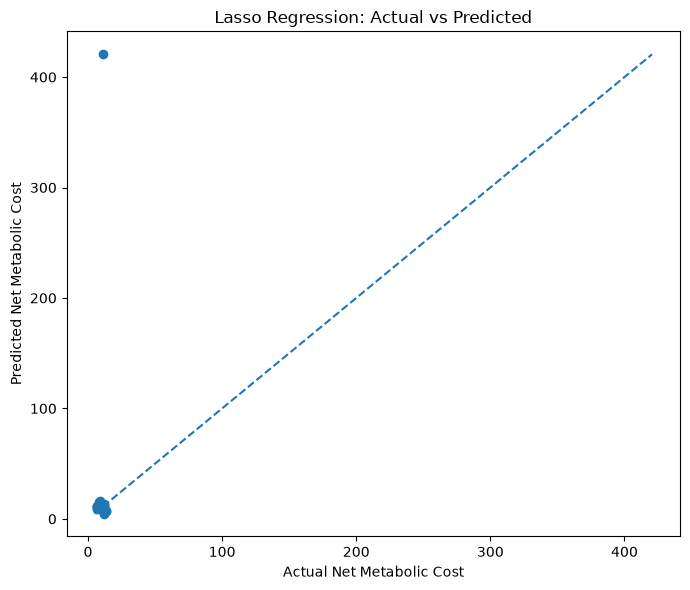

In [61]:
import matplotlib.pyplot as plt

# ============================================
# ACTUAL VS PREDICTED — LASSO
# ============================================

plt.figure(figsize=(7, 6))

plt.scatter(
    actual_values,
    predicted_values
)

# Perfect prediction line
min_value = min(
    actual_values.min(),
    predicted_values.min()
)

max_value = max(
    actual_values.max(),
    predicted_values.max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Net Metabolic Cost")
plt.ylabel("Predicted Net Metabolic Cost")
plt.title("Lasso Regression: Actual vs Predicted")

plt.tight_layout()

plt.savefig(
    "../figures/lasso_actual_vs_predicted.png",
    dpi=300
)

plt.show()

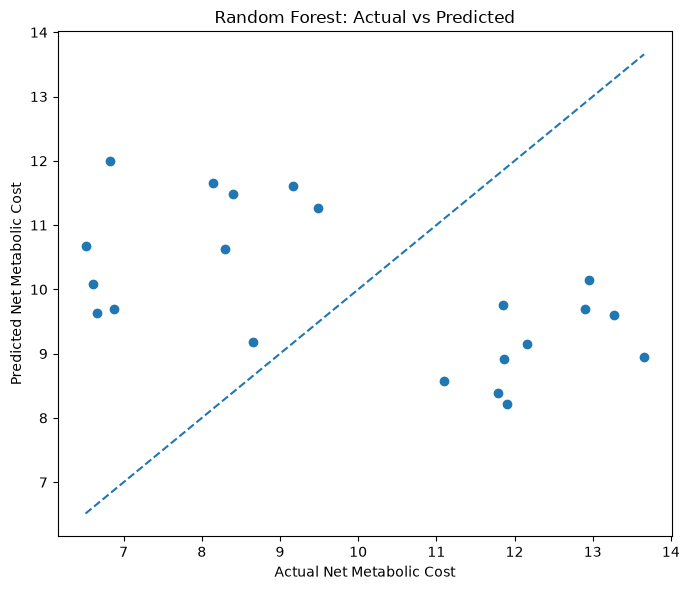

In [62]:
# ============================================
# ACTUAL VS PREDICTED — RANDOM FOREST
# ============================================

plt.figure(figsize=(7, 6))

plt.scatter(
    actual_rf,
    predicted_rf
)

min_value = min(
    actual_rf.min(),
    predicted_rf.min()
)

max_value = max(
    actual_rf.max(),
    predicted_rf.max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Net Metabolic Cost")
plt.ylabel("Predicted Net Metabolic Cost")
plt.title("Random Forest: Actual vs Predicted")

plt.tight_layout()

plt.savefig(
    "../figures/random_forest_actual_vs_predicted.png",
    dpi=300
)

plt.show()

In [66]:
# Remove Number_of_Final3min_Points as it is recording metadata

metadata_columns = [
    "Subject",
    "Condition",
    "EMG_File",
    "Time_Source",
    "Total_EMG_Duration_sec",
    "EMG_Final3min_Duration_sec",
    "EMG_Final3min_Rows",
    "Number_of_Final3min_Points",
    "Walking_VO2_Kg",
    "Standing_VO2_Kg",
    "Net_Metabolic_Cost"
]

clean_feature_columns = [
    col
    for col in final_ml_dataset.columns
    if col not in metadata_columns
]

X_clean = final_ml_dataset[
    clean_feature_columns
].copy()

y_clean = final_ml_dataset[
    "Net_Metabolic_Cost"
].copy()

groups_clean = final_ml_dataset[
    "Subject"
]

print("Clean feature matrix:", X_clean.shape)
print("Number of signal features:", len(clean_feature_columns))

print("\nMissing feature values:", X_clean.isnull().sum().sum())
print("Missing target values:", y_clean.isnull().sum())

Clean feature matrix: (21, 40)
Number of signal features: 40

Missing feature values: 0
Missing target values: 0


In [67]:
# ============================================
# STEP 26 — FINAL LASSO MODEL
# ============================================

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from sklearn.model_selection import GroupKFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Lasso pipeline
final_lasso = Pipeline([
    ("scaler", StandardScaler()),
    ("lasso", Lasso(alpha=0.1, max_iter=10000))
])

# Subject-based cross-validation
cv_final = GroupKFold(
    n_splits=min(6, groups_clean.nunique())
)

lasso_actual = []
lasso_predicted = []
lasso_results = []

for fold, (train_idx, test_idx) in enumerate(
    cv_final.split(X_clean, y_clean, groups=groups_clean),
    start=1
):

    X_train = X_clean.iloc[train_idx]
    X_test = X_clean.iloc[test_idx]

    y_train = y_clean.iloc[train_idx]
    y_test = y_clean.iloc[test_idx]

    # Train
    final_lasso.fit(X_train, y_train)

    # Predict
    y_pred = final_lasso.predict(X_test)

    lasso_actual.extend(y_test)
    lasso_predicted.extend(y_pred)

    # Metrics
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    lasso_results.append({
        "Fold": fold,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

# Overall results
lasso_actual = np.array(lasso_actual)
lasso_predicted = np.array(lasso_predicted)

final_lasso_mae = mean_absolute_error(
    lasso_actual,
    lasso_predicted
)

final_lasso_rmse = np.sqrt(
    mean_squared_error(
        lasso_actual,
        lasso_predicted
    )
)

final_lasso_r2 = r2_score(
    lasso_actual,
    lasso_predicted
)

print("======================================")
print("FINAL LASSO RESULTS")
print("======================================")

print(f"MAE  : {final_lasso_mae:.4f}")
print(f"RMSE : {final_lasso_rmse:.4f}")
print(f"R²   : {final_lasso_r2:.4f}")

print("\nFold results:")

final_lasso_folds = pd.DataFrame(lasso_results)

display(final_lasso_folds)

FINAL LASSO RESULTS
MAE  : 4.3847
RMSE : 4.8241
R²   : -2.8449

Fold results:


,Fold,MAE,RMSE,R2
0,1,6.115662,6.747677,-5.449362
1,2,2.563583,2.689558,-1.872806
2,3,5.623607,5.632939,-84.636841
3,4,2.561386,2.617573,-5.448174
4,5,4.289973,4.339723,-2.854762
5,6,5.216601,5.383930,-23.840538


In [68]:
# ============================================
# STEP 27 — FINAL RANDOM FOREST
# ============================================

from sklearn.ensemble import RandomForestRegressor

final_rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=3,
    min_samples_leaf=2,
    random_state=42
)

rf_actual = []
rf_predicted = []
rf_results = []

for fold, (train_idx, test_idx) in enumerate(
    cv_final.split(X_clean, y_clean, groups=groups_clean),
    start=1
):

    X_train = X_clean.iloc[train_idx]
    X_test = X_clean.iloc[test_idx]

    y_train = y_clean.iloc[train_idx]
    y_test = y_clean.iloc[test_idx]

    # Train
    final_rf.fit(X_train, y_train)

    # Predict
    y_pred = final_rf.predict(X_test)

    rf_actual.extend(y_test)
    rf_predicted.extend(y_pred)

    # Metrics
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    rf_results.append({
        "Fold": fold,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

# Overall predictions
rf_actual = np.array(rf_actual)
rf_predicted = np.array(rf_predicted)

final_rf_mae = mean_absolute_error(
    rf_actual,
    rf_predicted
)

final_rf_rmse = np.sqrt(
    mean_squared_error(
        rf_actual,
        rf_predicted
    )
)

final_rf_r2 = r2_score(
    rf_actual,
    rf_predicted
)

print("======================================")
print("FINAL RANDOM FOREST RESULTS")
print("======================================")

print(f"MAE  : {final_rf_mae:.4f}")
print(f"RMSE : {final_rf_rmse:.4f}")
print(f"R²   : {final_rf_r2:.4f}")

print("\nFold results:")

final_rf_folds = pd.DataFrame(rf_results)

display(final_rf_folds)

FINAL RANDOM FOREST RESULTS
MAE  : 3.1039
RMSE : 3.2904
R²   : -0.7888

Fold results:


,Fold,MAE,RMSE,R2
0,1,3.301695,3.349007,-0.588694
1,2,2.113422,2.502283,-1.486664
2,3,4.162480,4.240214,-47.525062
3,4,2.199140,2.265511,-3.830272
4,5,3.470722,3.553501,-1.584559
5,6,3.489117,3.593602,-10.066803


In [69]:
final_model_comparison = pd.DataFrame({
    "Model": [
        "Lasso Regression",
        "Random Forest"
    ],
    "MAE": [
        final_lasso_mae,
        final_rf_mae
    ],
    "RMSE": [
        final_lasso_rmse,
        final_rf_rmse
    ],
    "R2": [
        final_lasso_r2,
        final_rf_r2
    ]
})

display(
    final_model_comparison.round(4)
)

,Model,MAE,RMSE,R2
0,Lasso Regression,4.3847,4.8241,-2.8449
1,Random Forest,3.1039,3.2904,-0.7888


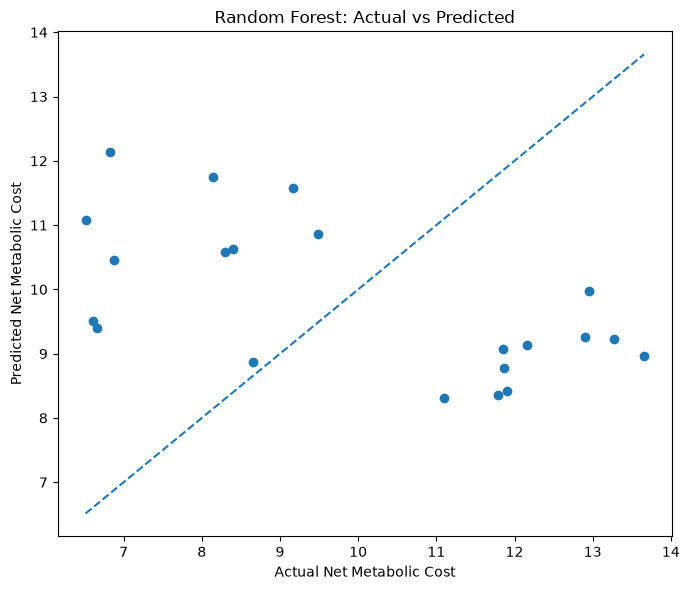

In [70]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))

plt.scatter(
    rf_actual,
    rf_predicted
)

# Perfect prediction line
min_value = min(
    rf_actual.min(),
    rf_predicted.min()
)

max_value = max(
    rf_actual.max(),
    rf_predicted.max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Net Metabolic Cost")
plt.ylabel("Predicted Net Metabolic Cost")
plt.title("Random Forest: Actual vs Predicted")

plt.tight_layout()

plt.savefig(
    "../figures/final_random_forest_actual_vs_predicted.png",
    dpi=300
)

plt.show()

In [71]:
import joblib
import os

# Train final RF using all available data
final_rf.fit(
    X_clean,
    y_clean
)

model_path = "../models/final_random_forest_model.pkl"

os.makedirs("../models", exist_ok=True)

joblib.dump(
    final_rf,
    model_path
)

print("Final model saved:")
print(model_path)

Final model saved:
../models/final_random_forest_model.pkl


In [72]:
import os

print(
    os.path.exists(
        "../data/processed/final_ml_dataset.csv"
    )
)

True
